# Annotation Benchmark Results — AP & AS vs. Annotation Budget

COCO AP and Average Similarity (AS), best-per-method from the grid search in
`label_spreading/baseline_comparison.py` over PLS/GKR/kNN/Bayes
hyperparameters (Baseline and Resort have none, so their single run is
already their best). AS is the strict variant returned by `evaluation.py` as
`AS_strict`: false positives receive zero similarity, which makes AS a
soft-label generalization of AP (see the `compute_similarity` docstring).
Sources:
`analysis/experiments/{coco_val,cityscapes_trainval,kitti_train,voc_trainval}_baseline_comp_simple/grid_search/*_grid_search_{results,best}.csv`.
`Resort`'s ground truth uses COCOeval's category-aware TP/FP matching
(`_category_aware_tp`) rather than the category-agnostic `gdino_match`.

In [1]:
import sys

import os 

os.makedirs("plots", exist_ok=True)

import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../utils")
from plot_layout import set_plot_layout

# LaTeX (Computer Modern) rendering + the repo-wide rcParams/figure defaults;
# requires a LaTeX installation with cm-super and dvipng.
set_plot_layout(path_to_latex="/home/klees/texlive/2024/bin/x86_64-linux")

pd.set_option("display.max_columns", None)

BEST_CSV = "experiments/coco_val_baseline_comp_simple/grid_search/coco_val_baseline_comp_simple_grid_search_best.csv"
grid_best = pd.read_csv(BEST_CSV)

# Marker shape distinguishes methods independently of color; the two
# no-hyperparameter baselines (Baseline, Resort) are drawn dashed.

METHOD_MARKERS = {"PLS": "o", "GKR": "s", "kNN": "^", "Bayes": "D", "Baseline": "v", "Resort": "P"}
METHOD_LINESTYLES = {"PLS": "-", "Bayes": "-", "GKR": "-", "kNN": "-",  "Baseline": "--", "Resort": "--"}
METHODS = ["PLS", "GKR", "kNN", "Baseline", "Resort", "Bayes"]

METHODS_TO_LABELS = {
    "PLS": "PLS",
    "GKR": "GKR",
    "kNN": "$k$-NN",
    "Bayes": "Bayesian PLS",
    "Baseline": "Calibrated GDino Score",
    "Resort": "Hard-Label Injection",
}

budgets = sorted(grid_best["budget"].unique())
budget_pct = [b * 100 for b in budgets]

## AS ceiling (why AS doesn't reach 1.0 even at 100% budget)

`Resort`/"Hard-Label Injection" reveals the true label only at the annotated
subset. This computes the same idea with *no* budget at all -- assign every
detection the true soft label of whichever GT box it best overlaps
(background otherwise), i.e. perfect oracle knowledge everywhere, still with
no propagation. It caps out well below 1.0 (and below `AR_100`) because AS
scores one fixed `p_hat` per detection against all 10 COCO IoU thresholds
(0.5:0.95) at once, while `AR_100` lets different redundant/duplicate raw
GDino proposals "hand off" the win at different thresholds -- GDino's
un-NMS'd, score>=0.2 proposals are often loosely localized, so a single
fixed assignment can't stay matched at the strict end of that range. Every
method in this plot submits exactly one such fixed `p_hat` too, so this is a
fair, apples-to-apples ceiling for all of them, not a shortcoming of any one
method. Cached after the first run.

In [2]:
import os
import sys

import numpy as np
import torch

sys.path.append("../label_spreading")
from evaluation import evaluate_result, _load_soft_gt_by_image, _iou_matrix

AS_CEILING_CSV = "experiments/coco_val_baseline_comp_simple/grid_search/coco_val_baseline_comp_simple_as_ceiling.csv"
DATASET_PATH = "../data/matched_dataset/coco_val_matched.parquet"
SOFT_GT_PATH = "../data/soft_datasets/soft_COCO_2017_val.json"
SCORE_THR = 0.2          # same detection-score prefilter as baseline_comparison.py
SOFT_LABEL_THRESH = 0.5  # only used by compute_ap here; AS itself uses the full un-thresholded soft GT

if os.path.exists(AS_CEILING_CSV):
    _ceiling_cached = pd.read_csv(AS_CEILING_CSV)
    as_ceiling = _ceiling_cached["AS_ceiling"].item()
    as_strict_ceiling = _ceiling_cached["AS_strict_ceiling"].item()
else:
    # No-propagation oracle ceiling (see the markdown above).
    #
    # Non-greedy on purpose: each detection independently takes the soft label of
    # whichever GT it overlaps most, as long as that best IoU clears 0.5 -- no
    # winner-take-all across detections competing for the same GT. A strict greedy
    # (one detection per GT) version undercounts this ceiling: compute_similarity
    # below re-matches detections to GT *independently at each of the 10 IoU
    # thresholds*, so a different one of several overlapping/duplicate raw GDino
    # boxes near the same object can be "the" match at a stricter threshold than
    # whichever single box greedy matching designated the winner -- that duplicate
    # would incorrectly be locked into a background label forever under greedy
    # matching, even though it's the genuine match at some threshold. Non-greedy
    # gives every such duplicate the oracle label, so this ceiling is never
    # undercut by exactly the kind of hand-off it's meant to explain.
    df_full = pd.read_parquet(DATASET_PATH)
    dataset = df_full[df_full["gdino_score"] >= SCORE_THR].copy().reset_index(drop=True)
    dataset["soft_label"] = list(np.array([v for v in dataset["soft_label"].values]))
    gt_by_image = _load_soft_gt_by_image(SOFT_GT_PATH)

    n_data = len(dataset)
    winner_mask = np.zeros(n_data, dtype=bool)
    winner_gt_soft = np.zeros((n_data, 81), dtype=np.float32)

    for image_id, rows in dataset.groupby("image_id"):
        idx = rows.index.to_numpy()
        gt = gt_by_image.get(image_id)
        if gt is None or len(gt["boxes"]) == 0:
            continue
        pred_boxes = torch.tensor(np.vstack(rows["gdino_bbox"].to_numpy()), dtype=torch.float32)
        gt_boxes = torch.tensor(gt["boxes"], dtype=torch.float32)
        gt_soft = gt["soft_labels"]
        iou_matrix = _iou_matrix(pred_boxes, gt_boxes).numpy()

        best_gt = iou_matrix.argmax(axis=1)
        best_iou = iou_matrix.max(axis=1)
        matched = best_iou >= 0.5
        winner_mask[idx[matched]] = True
        winner_gt_soft[idx[matched]] = gt_soft[best_gt[matched]]

    p_hat = np.zeros((n_data, 81), dtype=np.float64)
    p_hat[:, -1] = 1.0
    p_hat[winner_mask] = winner_gt_soft[winner_mask]
    p_hat = p_hat / p_hat.sum(axis=1, keepdims=True)

    raw_score = dataset["gdino_score"].to_numpy()
    # Oracle ranking, not just oracle labels: pin TP scores near 1.0 (tie-broken by raw
    # score, so TPs keep GDino's own relative order) and FP scores near 0 -- the same
    # convention `resorted_raw_baseline` ("Resort") applies to its budgeted subset.
    # Ranking by raw, uncalibrated gdino_score would understate the ceiling: AS_strict
    # gives FPs no credit, so it is sensitive to ranking quality, and the compared
    # methods' calibrated/propagated scores can out-rank raw score alone. This makes both
    # the labels *and* the ranking oracle-optimal.
    TP_TIE_BREAK_EPS = 1e-6
    pinned_score = raw_score.copy()
    pinned_score[winner_mask] = 1.0 - TP_TIE_BREAK_EPS * (1.0 - raw_score[winner_mask])
    # Non-winners: scaled down by the same eps rather than set to 0, which preserves
    # their relative (raw-score) order while staying below every winner. This matters
    # for the plain-AS ceiling also cached below (plain AS gives FPs graded TVD-based
    # credit).
    pinned_score[~winner_mask] = TP_TIE_BREAK_EPS * raw_score[~winner_mask]

    dataset_ceiling = dataset.copy()
    dataset_ceiling["p_hat"] = list(p_hat)
    dataset_ceiling["prediction"] = p_hat.argmax(axis=1)
    dataset_ceiling["score_est"] = list(np.stack([1.0 - pinned_score, pinned_score], axis=1))

    score = np.vstack(dataset_ceiling["score_est"].to_numpy())
    p_hat_mod = np.hstack([score[:, [1]] * (p_hat[:, :-1] / np.clip(1 - p_hat[:, -1:], 1e-12, None)), score[:, [0]]])
    dataset_ceiling["p_hat_mod"] = list(p_hat_mod)
    dataset_ceiling["prediction_mod"] = p_hat_mod.argmax(axis=1)
    dataset_ceiling.attrs["run_meta"] = dict(
        dataset_name="as_ceiling", only_objects=False, data_space="gdino_embedding",
        label_column="label", prob_label_column="soft_label", n_data=n_data, k=None, alpha=None,
        n_samples=int(winner_mask.sum()), config=None, elapsed_time=0.0, time_NN=0.0,
        time_graph=0.0, time_setup=0.0, time_solver=0.0, time_spread=0.0,
    )

    res = evaluate_result(dataset_ceiling, compute_ap=True, compute_as=True,
                           soft_gt_path=SOFT_GT_PATH, soft_label_thresh=SOFT_LABEL_THRESH).iloc[0]
    as_ceiling = float(res["AS"])
    as_strict_ceiling = float(res["AS_strict"])
    os.makedirs(os.path.dirname(AS_CEILING_CSV), exist_ok=True)
    pd.DataFrame([{"AS_ceiling": as_ceiling, "AS_strict_ceiling": as_strict_ceiling,
                   "AR_100_reference": float(res["AR_100"]),
                   "n_winners": int(winner_mask.sum()), "n_detections": n_data}]).to_csv(AS_CEILING_CSV, index=False)

ar_100_reference = pd.read_csv(AS_CEILING_CSV)["AR_100_reference"].item()
print(f"AS ceiling (oracle localization + labels, no propagation): {as_strict_ceiling:.4f}")
print(f"AR_100 of the same oracle assignment: {ar_100_reference:.4f}")


/home/klees/miniconda3/envs/label_spreading/lib/python3.11/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


AS ceiling (oracle localization + labels, no propagation): 0.4350
AR_100 of the same oracle assignment: 0.6135


In [3]:
# Column of the (strict) AS metric in grid_results, used by the per-row
# hyperparameter-study plots below.
AS = "AS_strict"

In [4]:
# Full grid-search results: one row per (method, budget, hyperparameter combination)

FULL_CSV = "experiments/coco_val_baseline_comp_simple/grid_search/coco_val_baseline_comp_simple_grid_search_results.csv"

BUDGETS_TO_DISPLAY = [0.01, 0.1, 1.0] # three budgets

grid_results = pd.read_csv(FULL_CSV)

grid_results.head()


,dataset,n_data,dim_reduction_technique,dimension,only_objects,prob_labels,alpha,n_samples,k,bandwidth_scale,RMSE,RMSE_mod,RMSE_match,RMSE_match_mod,Acc,Acc_match,Acc_mod,Acc_match_mod,TVD,TVD_match,TVD_mod,TVD_match_mod,MAE,MAE_match,MAE_mod,MAE_match_mod,runtime,time_NN,time_graph,time_setup,time_solver,time_spread,config,AP,AP50,AP75,AP_small,AP_medium,AP_large,AR_1,AR_10,AR_100,AR_small,AR_medium,AR_large,AP_sl,AP50_sl,AP75_sl,AP_small_sl,AP_medium_sl,AP_large_sl,AR_1_sl,AR_10_sl,AR_100_sl,AR_small_sl,AR_medium_sl,AR_large_sl,AS,AS_small,AS_medium,AS_large,AS_strict,AS_strict_small,AS_strict_medium,AS_strict_large,method,budget,gamma,kappa
0,coco_val_baseline_comp_simple_grid_PLS_b0.01_k...,85991,gdino,256,False,soft_label,0.05,859,10.0,0.1,0.299333,8.481916e+12,0.324899,1.145393e+13,0.646300,0.565276,0.621193,0.599353,0.531494,0.505309,1.201749e+12,2.337726e+12,0.013123,0.012477,2.967282e+10,5.772163e+10,1.318735,0.394504,0.047755,0.061128,0.545845,0.354848,./configs/FGMRES_AGGREGATION.json,0.401992,0.571655,0.429065,0.187141,0.400624,0.633527,0.342059,0.563964,0.613451,0.364053,0.622425,0.827844,0.384893,0.554428,0.409122,0.186585,0.391905,0.611106,0.339440,0.562975,0.613436,0.364022,0.622400,0.827850,0.299080,0.165207,0.371650,0.485325,0.226993,0.098317,0.303423,0.422040,PLS,0.01,NaN,NaN
1,coco_val_baseline_comp_simple_grid_PLS_b0.01_k...,85991,gdino,256,False,soft_label,0.10,859,10.0,0.1,0.169998,5.091426e+10,0.087742,1.452174e+10,0.664139,0.582277,0.647498,0.607690,0.484268,0.415659,7.770417e+09,3.408124e+09,0.011957,0.010263,1.918621e+08,8.415122e+07,1.565300,0.521185,0.064776,0.058859,0.645940,0.468120,./configs/FGMRES_AGGREGATION.json,0.426495,0.597469,0.456477,0.189068,0.422678,0.658934,0.346339,0.565046,0.613475,0.364033,0.622480,0.827824,0.398686,0.571976,0.424665,0.182755,0.406915,0.631898,0.340747,0.563393,0.613452,0.364038,0.622431,0.827848,0.324800,0.177914,0.399565,0.550737,0.263096,0.108066,0.333537,0.515073,PLS,0.01,NaN,NaN
2,coco_val_baseline_comp_simple_grid_PLS_b0.01_k...,85991,gdino,256,False,soft_label,0.20,859,10.0,0.1,0.060585,2.969123e+08,0.068439,1.404719e+08,0.670326,0.574799,0.658511,0.607993,0.458504,0.409309,5.823544e+07,2.948045e+07,0.011321,0.010106,1.437912e+06,7.279124e+05,1.177420,0.388854,0.071737,0.008146,0.389890,0.254843,./configs/FGMRES_AGGREGATION.json,0.425486,0.596069,0.455258,0.188970,0.420980,0.660011,0.346401,0.565134,0.613473,0.364033,0.622473,0.827824,0.403651,0.576987,0.431265,0.186306,0.410266,0.628340,0.341415,0.563804,0.613444,0.364023,0.622420,0.827822,0.333681,0.183342,0.404159,0.568014,0.258949,0.105410,0.323004,0.517521,PLS,0.01,NaN,NaN
3,coco_val_baseline_comp_simple_grid_PLS_b0.01_k...,85991,gdino,256,False,soft_label,0.30,859,10.0,0.1,0.060921,1.783256e+09,0.067418,1.051863e+09,0.665011,0.570909,0.659883,0.607033,0.458683,0.408311,4.359347e+08,2.449301e+08,0.011326,0.010082,1.076382e+07,6.047657e+06,1.339080,0.402549,0.074002,0.056119,0.533607,0.371066,./configs/FGMRES_AGGREGATION.json,0.431458,0.602898,0.462010,0.188938,0.426381,0.667667,0.346236,0.565185,0.613477,0.364031,0.622473,0.827829,0.396893,0.567209,0.423204,0.184872,0.405312,0.629896,0.341471,0.563368,0.613447,0.364037,0.622419,0.827818,0.330875,0.180938,0.400170,0.568452,0.261618,0.105708,0.325410,0.519470,PLS,0.01,NaN,NaN
4,coco_val_baseline_comp_simple_grid_PLS_b0.01_k...,85991,gdino,256,False,soft_label,0.40,859,10.0,0.1,0.060354,2.010643e+09,0.065795,1.025206e+08,0.670803,0.581392,0.664942,0.611049,0.455044,0.400407,3.933045e+08,2.859579e+07,0.011236,0.009887,9.711222e+06,7.060688e+05,1.911398,0.464877,0.071127,0.058321,1.042759,0.878504,./configs/FGMRES_AGGREGATION.json,0.431669,0.602768,0.462172,0.189647,0.426187,0.667978,0.346661,0.564985,0.613481,0.364042,0.622473,0.827829,0.406167,0.579813,0.433755,0.185067,0.412885,0.635576,0.342278,0.563798,0.613455,0.364040,0.622413,0.827829,0.334614,0.180568,0.406639,0.577428,0.267636,0.107379,0.334019,0.531123,PLS,0.01,NaN,NaN


# COCO: AS & AP vs. budget

One AS-vs-budget and one AP-vs-budget plot, all six methods
(PLS/GKR/kNN/Bayes/Baseline/Resort) as separate lines. The best value per
(method, budget) is derived from the full grid-search results
(`best_of`/`best_metrics_table` below), since
`*_grid_search_best.csv` only contains `best_AP` and plain `best_AS`, not
`best_AS_strict`.

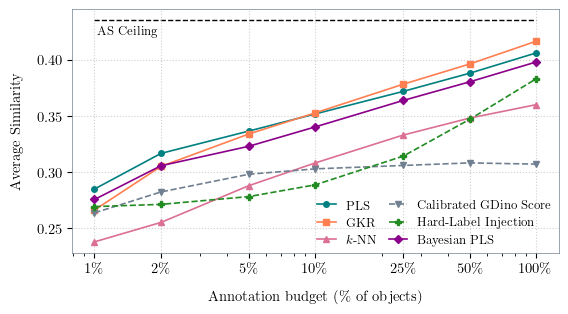

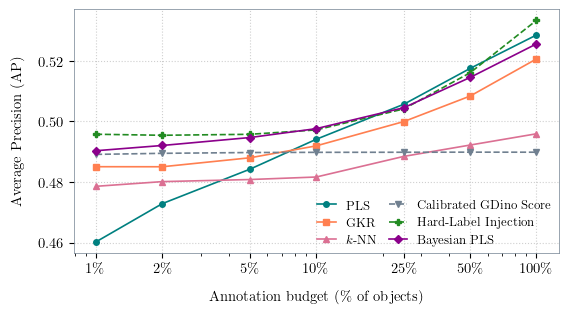

In [5]:
SWEEP_FIGSIZE = (5.8, (9 / 16) * 5.8 )   # default size of the vs.-budget plots


def best_of(df, metric):
    """Best value of `metric` per (method, budget) over all hyperparameter
    combinations in the full grid-search results."""
    return (df.sort_values(metric, ascending=False)
              .groupby(["method", "budget"], as_index=False).first()
              [["method", "budget", metric]]
              .rename(columns={metric: f"best_{metric}"}))


def best_metrics_table(full_df):
    """best_AP/best_AS/best_AS_strict, one row per (method, budget), each metric
    with its own best hyperparameters."""
    tables = [best_of(full_df, m) for m in ["AP", "AS", "AS_strict"]]
    out = tables[0]
    for t in tables[1:]:
        out = out.merge(t, on=["method", "budget"])
    return out


def plot_metric_vs_budget(display_name, dataset_key, best_df, metric, y_label, out_prefix,
                           ceiling=None, ceiling_label=None, figsize=None, show_legend=True,
                           show_title=True, legend_fontsize=9, ceiling_fontsize=8,
                           markersize=4, linewidth=1.2, legend_loc="lower right",
                           legend_bbox_to_anchor=(1.0, 0.0), save=True):
    """Per-dataset, per-metric vs. budget plot -- one figure, all methods as
    separate lines, optional oracle-ceiling line (labeled by a text annotation,
    not a legend entry). figsize defaults to SWEEP_FIGSIZE; show_legend=False lets
    side-by-side panels (e.g. Cityscapes/KITTI/VOC sharing one legend) skip their
    own legend. show_title=False drops the in-plot title (e.g. when the dataset
    name is given by a LaTeX \subcaption instead). ceiling_label=None still draws
    the ceiling line but skips its text label. The ceiling label is offset in
    points (not data units), so it stays legible regardless of figsize or the
    dataset's y-range."""
    col = f"best_{metric}"
    fig, ax = plt.subplots(figsize=figsize if figsize is not None else SWEEP_FIGSIZE)
    method_lines = []
    for method in METHODS:
        sub = best_df[best_df["method"] == method].sort_values("budget")
        line, = ax.plot(sub["budget"] * 100, sub[col], marker=METHOD_MARKERS[method],
                         linestyle=METHOD_LINESTYLES[method], markersize=markersize, linewidth=linewidth,
                         label=METHODS_TO_LABELS[method])
        method_lines.append(line)
    ax.set_xscale("log")
    ax.set_xticks(budget_pct)
    ax.set_xticklabels([rf"{b:g}\%" for b in budget_pct])
    ax.set_xlabel(r"Annotation budget (\% of objects)")
    ax.set_ylabel(y_label)
    if show_title:
        ax.set_title(display_name)
    ax.grid(True, ls=":", alpha=0.6)
    if show_legend:
        ax.legend(handles=method_lines, fontsize=legend_fontsize, frameon=False, ncols=2, loc=legend_loc,
                  bbox_to_anchor=legend_bbox_to_anchor, borderaxespad=0.15, columnspacing=1.0, handlelength=1.5)
    if ceiling is not None:
        ax.hlines(ceiling, xmin=1, xmax=100, color="black", linestyle="dashed", linewidth=1.0, zorder=1)
        if ceiling_label is not None:
            ax.annotate(ceiling_label, xy=(1, ceiling), xytext=(2, -4), textcoords="offset points",
                        fontsize=ceiling_fontsize, color="black", va="top", ha="left")
    plt.tight_layout()
    if save:
        plt.savefig(f"plots/{out_prefix}_{dataset_key}.pdf", dpi=300, bbox_inches="tight")
    plt.show()


# best_tables is built up incrementally -- COCO here, the other three datasets
# in the next section -- and reused by the summary table at the end.
best_tables = {"coco_val": best_metrics_table(grid_results)}

plot_metric_vs_budget("COCO", "coco_val", best_tables["coco_val"], "AS_strict",
                       "Average Similarity", "AS_comparison",
                       ceiling=as_strict_ceiling, ceiling_label="AS Ceiling", show_title=False,
                       ceiling_fontsize=9)
plot_metric_vs_budget("COCO", "coco_val", best_tables["coco_val"], "AP",
                       "Average Precision (AP)", "AP_comparison", show_title=False)


# Cityscapes, KITTI & Pascal VOC: AS & AP vs. budget

Same AS-vs-budget and AP-vs-budget plots as the COCO section above,
same six methods, same grid search (PLS/GKR/kNN/Bayes hyperparameters,
Baseline/Resort single-run), same AS-ceiling definition (oracle localization +
labels, no propagation) -- just re-run per dataset. Sources:
`analysis/experiments/{cityscapes_trainval,kitti_train,voc_trainval}_baseline_comp_simple/grid_search/*_grid_search_results.csv`.

In [6]:
OTHER_DATASETS = {
    "cityscapes_trainval": dict(
        display_name="Cityscapes",
        matched_path="../data/matched_dataset/cityscapes_trainval_matched.parquet",
        soft_gt_path="../data/soft_datasets/soft_Cityscapes_trainval_fixed.json",
    ),
    "kitti_train": dict(
        display_name="KITTI",
        matched_path="../data/matched_dataset/kitti_train_matched.parquet",
        soft_gt_path="../data/soft_datasets/soft_Kitti_2D_train_fixed.json",
    ),
    "voc_trainval": dict(
        display_name="Pascal VOC",
        matched_path="../data/matched_dataset/pascal_voc_trainval_matched.parquet",
        soft_gt_path="../data/soft_datasets/soft_PascalVOC_2012_detection_trainval_fixed.json",
    ),
}


def compute_as_ceiling(dataset_key, matched_path, soft_gt_path):
    """Same oracle-localization-and-labels, no-propagation ceiling as the COCO
    AS-ceiling cell above, generalized to any dataset's matched_dataset parquet +
    soft-GT json (soft_label dimensionality read off the data instead of hardcoded
    to COCO's 81, since Cityscapes/KITTI/VOC have far fewer classes). Cached to its
    own per-dataset CSV after the first run. Returns {"AS_ceiling": ..., "AS_strict_ceiling": ...}."""
    cache_csv = (f"experiments/{dataset_key}_baseline_comp_simple/grid_search/"
                 f"{dataset_key}_baseline_comp_simple_as_ceiling.csv")
    if os.path.exists(cache_csv):
        _cached = pd.read_csv(cache_csv)
        return {"AS_ceiling": _cached["AS_ceiling"].item(),
                "AS_strict_ceiling": _cached["AS_strict_ceiling"].item()}

    df_full = pd.read_parquet(matched_path)
    dataset = df_full[df_full["gdino_score"] >= SCORE_THR].copy().reset_index(drop=True)
    dataset["soft_label"] = list(np.array([v for v in dataset["soft_label"].values]))
    gt_by_image = _load_soft_gt_by_image(soft_gt_path)

    n_data = len(dataset)
    n_classes = len(dataset["soft_label"].iloc[0])
    winner_mask = np.zeros(n_data, dtype=bool)
    winner_gt_soft = np.zeros((n_data, n_classes), dtype=np.float32)

    # Non-greedy: each detection independently takes the soft label of whichever
    # GT it overlaps most, as long as that best IoU clears 0.5 -- no
    # winner-take-all across detections competing for the same GT (see the
    # markdown/comment on the COCO AS-ceiling cell above for why a strict
    # greedy, one-detection-per-GT assignment undercounts this ceiling).
    for image_id, rows in dataset.groupby("image_id"):
        idx = rows.index.to_numpy()
        gt = gt_by_image.get(image_id)
        if gt is None or len(gt["boxes"]) == 0:
            continue
        pred_boxes = torch.tensor(np.vstack(rows["gdino_bbox"].to_numpy()), dtype=torch.float32)
        gt_boxes = torch.tensor(gt["boxes"], dtype=torch.float32)
        gt_soft = gt["soft_labels"]
        iou_matrix = _iou_matrix(pred_boxes, gt_boxes).numpy()

        best_gt = iou_matrix.argmax(axis=1)
        best_iou = iou_matrix.max(axis=1)
        matched = best_iou >= 0.5
        winner_mask[idx[matched]] = True
        winner_gt_soft[idx[matched]] = gt_soft[best_gt[matched]]

    p_hat = np.zeros((n_data, n_classes), dtype=np.float64)
    p_hat[:, -1] = 1.0
    p_hat[winner_mask] = winner_gt_soft[winner_mask]
    p_hat = p_hat / p_hat.sum(axis=1, keepdims=True)

    raw_score = dataset["gdino_score"].to_numpy()
    # Oracle ranking (TPs pinned near 1.0, FPs near 0) -- see the COCO AS-ceiling cell.
    TP_TIE_BREAK_EPS = 1e-6
    pinned_score = raw_score.copy()
    pinned_score[winner_mask] = 1.0 - TP_TIE_BREAK_EPS * (1.0 - raw_score[winner_mask])
    pinned_score[~winner_mask] = TP_TIE_BREAK_EPS * raw_score[~winner_mask]

    dataset_ceiling = dataset.copy()
    dataset_ceiling["p_hat"] = list(p_hat)
    dataset_ceiling["prediction"] = p_hat.argmax(axis=1)
    dataset_ceiling["score_est"] = list(np.stack([1.0 - pinned_score, pinned_score], axis=1))

    score = np.vstack(dataset_ceiling["score_est"].to_numpy())
    p_hat_mod = np.hstack([score[:, [1]] * (p_hat[:, :-1] / np.clip(1 - p_hat[:, -1:], 1e-12, None)), score[:, [0]]])
    dataset_ceiling["p_hat_mod"] = list(p_hat_mod)
    dataset_ceiling["prediction_mod"] = p_hat_mod.argmax(axis=1)
    dataset_ceiling.attrs["run_meta"] = dict(
        dataset_name=f"{dataset_key}_as_ceiling", only_objects=False, data_space="gdino_embedding",
        label_column="label", prob_label_column="soft_label", n_data=n_data, k=None, alpha=None,
        n_samples=int(winner_mask.sum()), config=None, elapsed_time=0.0, time_NN=0.0,
        time_graph=0.0, time_setup=0.0, time_solver=0.0, time_spread=0.0,
    )

    res = evaluate_result(dataset_ceiling, compute_ap=True, compute_as=True,
                           soft_gt_path=soft_gt_path, soft_label_thresh=SOFT_LABEL_THRESH).iloc[0]
    as_ceiling = float(res["AS"])
    as_strict_ceiling = float(res["AS_strict"])
    os.makedirs(os.path.dirname(cache_csv), exist_ok=True)
    pd.DataFrame([{"AS_ceiling": as_ceiling, "AS_strict_ceiling": as_strict_ceiling,
                   "AR_100_reference": float(res["AR_100"]),
                   "n_winners": int(winner_mask.sum()), "n_detections": n_data}]).to_csv(cache_csv, index=False)
    return {"AS_ceiling": as_ceiling, "AS_strict_ceiling": as_strict_ceiling}



Cityscapes: AS ceiling = 0.4136


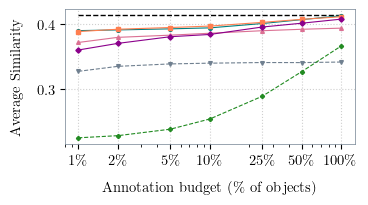

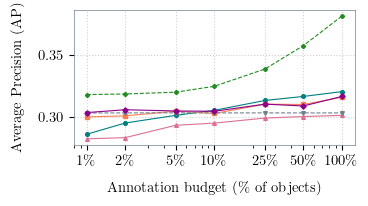

KITTI: AS ceiling = 0.4746


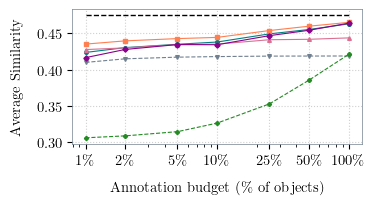

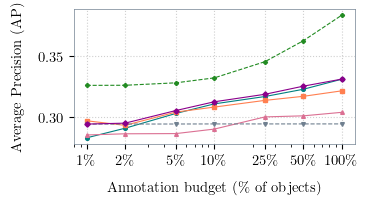

Pascal VOC: AS ceiling = 0.6837


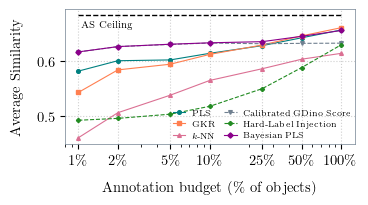

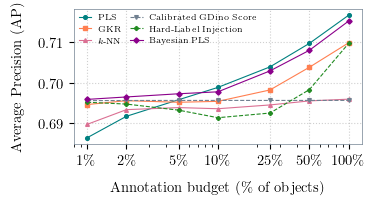

In [7]:
other_grid_bests = {}
other_full_results = {}
other_as_ceilings = {}

for dataset_key, cfg in OTHER_DATASETS.items():
    best_csv = (f"experiments/{dataset_key}_baseline_comp_simple/grid_search/"
                f"{dataset_key}_baseline_comp_simple_grid_search_best.csv")
    full_csv = (f"experiments/{dataset_key}_baseline_comp_simple/grid_search/"
                f"{dataset_key}_baseline_comp_simple_grid_search_results.csv")
    other_grid_bests[dataset_key] = pd.read_csv(best_csv)
    other_full_results[dataset_key] = pd.read_csv(full_csv)

    ceilings_d = compute_as_ceiling(dataset_key, cfg["matched_path"], cfg["soft_gt_path"])
    other_as_ceilings[dataset_key] = ceilings_d
    print(f"{cfg['display_name']}: AS ceiling = {ceilings_d['AS_strict_ceiling']:.4f}")

    best_tables[dataset_key] = best_metrics_table(other_full_results[dataset_key])

    # 2/3-scaled for side-by-side inclusion (Cityscapes | KITTI | Pascal VOC); legend
    # and "AS Ceiling" text only on Pascal VOC (last/rightmost panel), since all three
    # share the same methods/ceiling definition -- no in-plot title either, since the
    # dataset name is given by each panel's \subcaption in the paper's side-by-side
    # figure instead. Smaller legend/ceiling fonts to match the shrunk figsize.
    other_figsize = (SWEEP_FIGSIZE[0] * 2 / 3, SWEEP_FIGSIZE[1] * 2 / 3)
    is_voc = dataset_key == "voc_trainval"
    other_markersize = 4 * 2 / 3
    other_linewidth = 1.2 * 2 / 3

    plot_metric_vs_budget(cfg["display_name"], dataset_key, best_tables[dataset_key], "AS_strict",
                           "Average Similarity", "AS_comparison",
                           ceiling=ceilings_d["AS_strict_ceiling"], ceiling_label="AS Ceiling" if is_voc else None,
                           figsize=other_figsize, show_legend=is_voc, show_title=False,
                           legend_fontsize=6, ceiling_fontsize=7,
                           markersize=other_markersize, linewidth=other_linewidth)
    # AP has no ceiling line, so the top-left corner is free -- put the (VOC-only)
    # legend there instead of bottom-right, where VOC's AP curves cluster densely.
    plot_metric_vs_budget(cfg["display_name"], dataset_key, best_tables[dataset_key], "AP",
                           "Average Precision (AP)", "AP_comparison",
                           figsize=other_figsize, show_legend=is_voc, show_title=False,
                           legend_fontsize=6, ceiling_fontsize=7,
                           markersize=other_markersize, linewidth=other_linewidth,
                           legend_loc="upper left", legend_bbox_to_anchor=(0.0, 1.0))


# Annotation cost per dataset

Estimated annotation time of our approach at 1%, 10% and 100% budget, compared to the
fully manual construction of the soft-label datasets. Every budget draw in the grid
search is one simulated annotator answer (a one-hot vote sampled from that detection's
soft label), so a budget costs `max(1, int(n_pool * budget))` answers -- `n_pool` the
score-filtered detection pool (`gdino_score >= SCORE_THR`) -- times the dataset's median
answer time. The median is taken over every recorded answer (`annotation_info[*][*]["time"]`)
in that dataset's soft-GT json; it is used instead of the mean because the recorded times
are long-tailed (e.g. annotators pausing mid-task; mean and median are printed below). The fully
manual cost is the total logged annotation time of the soft-label datasets (`MANUAL_HOURS`
below, entered by hand). Answer-time stats are cached per dataset to
`experiments/{dataset}_baseline_comp_simple/grid_search/{dataset}_baseline_comp_simple_answer_time.csv`.

In [8]:
import json

COST_DATASETS = {
    "coco_val": dict(display_name="COCO", matched_path=DATASET_PATH, soft_gt_path=SOFT_GT_PATH),
    **OTHER_DATASETS,
}
COST_BUDGETS = [0.01, 0.1, 1.0]
# total logged annotation time (h) of fully manual soft-label annotation per dataset,
# summed by hand from the annotation campaign's logged working times
MANUAL_HOURS = {"coco_val": 2005.4, "cityscapes_trainval": 992.2, "kitti_train": 1306.9, "voc_trainval": 1016.9}


def answer_time_stats(dataset_key, matched_path, soft_gt_path):
    """Mean/median time per single annotator answer (seconds) over all objects of a
    soft-GT json, plus the score-filtered detection pool size the budgets refer to.
    Cached to its own per-dataset CSV after the first run (the soft-GT jsons are large)."""
    cache_csv = (f"experiments/{dataset_key}_baseline_comp_simple/grid_search/"
                 f"{dataset_key}_baseline_comp_simple_answer_time.csv")
    if os.path.exists(cache_csv):
        return pd.read_csv(cache_csv).iloc[0].to_dict()
    with open(soft_gt_path) as f:
        soft_gt = json.load(f)
    times = np.array([answer["time"]
                      for objects in soft_gt["objects"].values() for obj in objects
                      for answers in obj["annotation_info"].values() for answer in answers])
    scores = pd.read_parquet(matched_path, columns=["gdino_score"])["gdino_score"]
    stats = dict(n_pool=int((scores >= SCORE_THR).sum()), n_answers=len(times),
                 mean_answer_time=times.mean(), median_answer_time=np.median(times))
    pd.DataFrame([stats]).to_csv(cache_csv, index=False)
    return stats


def cost_hours(stats, budget):
    """Same number of draws as sample_budget_indices, times the median answer time."""
    return max(1, int(stats["n_pool"] * budget)) * stats["median_answer_time"] / 3600


answer_times = {key: answer_time_stats(key, cfg["matched_path"], cfg["soft_gt_path"])
                for key, cfg in COST_DATASETS.items()}
cost_df = pd.DataFrame({
    cfg["display_name"]: {"median_answer_time": answer_times[key]["median_answer_time"],
                          **{f"{b * 100:g}%": cost_hours(answer_times[key], b) for b in COST_BUDGETS},
                          "manual": MANUAL_HOURS[key]}
    for key, cfg in COST_DATASETS.items()
}).T
display(cost_df.round(3))
for key, cfg in COST_DATASETS.items():
    s = answer_times[key]
    print(f"{cfg['display_name']}: mean answer time {s['mean_answer_time']:.2f} s, "
          f"median {s['median_answer_time']:.2f} s ({int(s['n_answers']):,} answers)")

# needs \usepackage{booktabs} and \usepackage{graphicx} (for \resizebox)
budget_headers = " & ".join(rf"{b * 100:g}\%" for b in COST_BUDGETS)
rows = []
for name, r in cost_df.iterrows():
    costs = " & ".join(f"{r[f'{b * 100:g}%']:.1f}" for b in COST_BUDGETS)
    rows.append(f"{name} & {r['median_answer_time']:.2f} & {costs} & {r['manual']:,.1f} \\\\")
cost_table = "\n".join([
    r"\begin{table}[t]",
    r"\centering",
    r"\caption{Estimated annotation costs for our approach depending on the dataset and annotation "
    r"budget. The estimate is based on each dataset's median answer time per object and is compared to "
    r"the annotation costs of fully manual annotation with soft labels as done by~\cite{benchmark}.}",
    r"\label{tab:annotation_cost}",
    r"\resizebox{\linewidth}{!}{",
    r"\begin{tabular}{llrrrr}",
    r"\toprule",
    r" & Median & \multicolumn{3}{c}{Cost at budget (h)} & Fully manual \\",
    r"\cmidrule(lr){3-5}",
    rf"Dataset &  answer time (s) & {budget_headers} & annotation (h) \\",
    r"\midrule",
    *rows,
    r"\bottomrule",
    r"\end{tabular}",
    r"}",
    r"\end{table}",
])
print(cost_table)

os.makedirs("tables", exist_ok=True)
with open("tables/annotation_cost.tex", "w") as f:
    f.write(f"%% ---- annotation cost table ----\n{cost_table}\n")
print("Saved -> analysis/tables/annotation_cost.tex")

,median_answer_time,1%,10%,100%,manual
COCO,1.139,0.272,2.721,27.207,2005.4
Cityscapes,0.820,0.177,1.770,17.702,992.2
KITTI,1.004,0.279,2.787,27.868,1306.9
Pascal VOC,0.870,0.141,1.409,14.087,1016.9


COCO: mean answer time 2.28 s, median 1.14 s (966,075 answers)
Cityscapes: mean answer time 1.73 s, median 0.82 s (828,564 answers)
KITTI: mean answer time 1.99 s, median 1.00 s (1,116,544 answers)
Pascal VOC: mean answer time 1.84 s, median 0.87 s (520,784 answers)
\begin{table}[t]
\centering
\caption{Estimated annotation costs for our approach depending on the dataset and annotation budget. The estimate is based on each dataset's median answer time per object and is compared to the annotation costs of fully manual annotation with soft labels as done by~\cite{benchmark}.}
\label{tab:annotation_cost}
\resizebox{\linewidth}{!}{
\begin{tabular}{llrrrr}
\toprule
 & Median & \multicolumn{3}{c}{Cost at budget (h)} & Fully manual \\
\cmidrule(lr){3-5}
Dataset &  answer time (s) & 1\% & 10\% & 100\% & annotation (h) \\
\midrule
COCO & 1.14 & 0.3 & 2.7 & 27.2 & 2,005.4 \\
Cityscapes & 0.82 & 0.2 & 1.8 & 17.7 & 992.2 \\
KITTI & 1.00 & 0.3 & 2.8 & 27.9 & 1,306.9 \\
Pascal VOC & 0.87 & 0.1 & 1.4 

# From score to annotations: precision-recall at 1% budget (COCO)

Bridges the AS/AP results above to a concrete "how many objects get annotated,
at what false-positive cost" statement -- the question that matters once a
threshold is applied to turn scores into a final annotation set. Uses the same
1% budget convention as the grid search above (1% of the score-filtered
detection pool, `sample_budget_indices`, not a per-image budget) and the same
hyperparameters the grid search used at that budget: PLS's best-RMSE fit,
which `Bayes` blends on top of, and the best-AP `kappa` -- so these are the
scores behind the `Bayes` AP reported at 1% budget, not a separate ad hoc run.

Precision-recall is computed over the unlabeled remainder only (the budgeted
1%'s own labels are already known, not predicted). Two threshold choices are
marked on the curve: a fixed 0.5, and the F1-optimal threshold found on the
budgeted ("training") subset itself, applied out of sample -- F1 measured on
the subset the threshold was chosen on would be optimistic.

In [9]:
sys.path.append("../label_spreading")
from baseline_comparison import sample_budget_indices, calibrated_gdino_baseline, build_bayes_dataset
from src import label_spreading_object_conventional

PR_BUDGET = 0.01
PR_AMGX_CONFIG = "../label_spreading/configs/FGMRES_AGGREGATION.json"

# Independent load -- cell 3 above only loads df_full/dataset/gt_by_image on a cache
# miss for the AS-ceiling computation, so they may not be in scope here.
pr_df_full = pd.read_parquet(DATASET_PATH)
pr_dataset = pr_df_full[pr_df_full["gdino_score"] >= SCORE_THR].copy().reset_index(drop=True)
sl = np.array([v for v in pr_dataset["soft_label"].values])
pr_dataset["soft_label"] = list(sl)
pr_dataset["is_object"] = pr_dataset["gdino_match"].astype(float)
pr_gt_by_image = _load_soft_gt_by_image(SOFT_GT_PATH)

print(f"{len(pr_dataset):,} detections across {pr_dataset['image_id'].nunique():,} images")

85,991 detections across 4,992 images


In [10]:
# Same hyperparameter selection as the grid search itself: PLS's best-RMSE fit
# (what `Bayes` blends on top of), and whichever kappa scored best AP at this budget.
pls_at_budget = grid_results[(grid_results["method"] == "PLS") & (grid_results["budget"] == PR_BUDGET)]
pls_hp = pls_at_budget.loc[pls_at_budget["RMSE"].idxmin()]
PR_K, PR_ALPHA, PR_BANDWIDTH = int(pls_hp["k"]), float(pls_hp["alpha"]), float(pls_hp["bandwidth_scale"])

bayes_at_budget = grid_results[(grid_results["method"] == "Bayes") & (grid_results["budget"] == PR_BUDGET)]
PR_KAPPA = float(bayes_at_budget.loc[bayes_at_budget["AP"].idxmax(), "kappa"])

print(f"PLS (best-RMSE): k={PR_K}  alpha={PR_ALPHA}  bandwidth_scale={PR_BANDWIDTH}")
print(f"Bayes kappa (best-AP): {PR_KAPPA}")

pr_indices = sample_budget_indices(len(pr_dataset), PR_BUDGET)   # seed=42 default, same as the grid search
pr_budget_mask = np.zeros(len(pr_dataset), dtype=bool)
pr_budget_mask[np.unique(pr_indices)] = True
print(f"Budget: {int(pr_budget_mask.sum()):,} unique detections ({pr_budget_mask.mean():.1%} of the pool)")

pls_result = label_spreading_object_conventional(
    "pr_takeaway_pls", only_objects=False, dataset=pr_dataset.copy(), data_space="gdino_embedding",
    label_column="label", prob_label_column="soft_label", score_column="is_object",
    n_data="all", k=PR_K, alpha=PR_ALPHA, n_samples=len(pr_indices), indices=pr_indices,
    config=PR_AMGX_CONFIG, bandwidth_scale=PR_BANDWIDTH,
)

baseline_ds, p_hat_baseline = calibrated_gdino_baseline(
    pr_dataset, pr_df_full, PR_BUDGET, "pr_takeaway_baseline", False, "gdino_embedding",
)

pls_trials = pls_result["trials"].to_numpy()
pls_p_hat = np.vstack(pls_result["p_hat"].to_numpy())
F_pls = pls_p_hat * pls_trials[:, None]
bayes_ds = build_bayes_dataset(
    PR_KAPPA, p_hat_baseline, F_pls, pls_result, "pr_takeaway_bayes",
    PR_K, PR_ALPHA, len(pr_indices), False, "gdino_embedding", PR_AMGX_CONFIG,
)

print("Done: baseline_ds, pls_result, bayes_ds all carry score_est/p_hat for the full dataset.")

PLS (best-RMSE): k=20  alpha=0.9  bandwidth_scale=1.0
Bayes kappa (best-AP): 1.0
Budget: 856 unique detections (1.0% of the pool)
use pre-defined indices


Done: baseline_ds, pls_result, bayes_ds all carry score_est/p_hat for the full dataset.


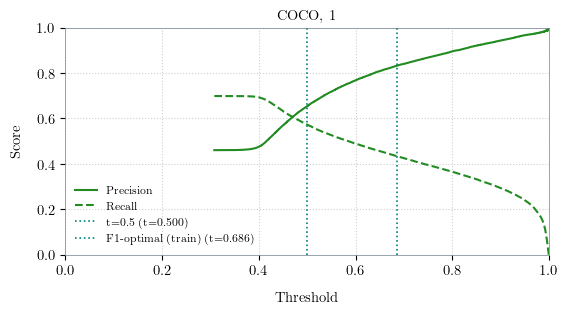

Precision  Recall      F1  n_annotations
Threshold          Population                                          
t=0.5              All            0.6570  0.5801  0.6162          49498
                   Small          0.5671  0.3453  0.4293          16074
                   Medium         0.6653  0.7069  0.6854          18056
                   Large          0.7414  0.8989  0.8126          15368
F1-optimal (train) All            0.8350  0.4410  0.5772          29609
                   Small          0.7587  0.2050  0.3228           7132
                   Medium         0.8326  0.5334  0.6502          10887
                   Large          0.8843  0.8085  0.8447          11590

In [11]:
from sklearn.metrics import precision_recall_curve

y_true = pr_dataset["gdino_match"].to_numpy()
held_out = ~pr_budget_mask   # genuinely unlabeled remainder -- the population this section is actually about
bayes_scores = np.vstack(bayes_ds["score_est"].to_numpy())[:, 1]

# Two threshold choices: fixed 0.5, and F1-optimal found on the budgeted subset itself
# (circular by construction -- see the markdown above), both then applied out-of-sample
# to the held-out population to see what they actually deliver.
prec_train, rec_train, thr_train = precision_recall_curve(y_true[pr_budget_mask], bayes_scores[pr_budget_mask])
f1_train = np.where((prec_train + rec_train) > 0, 2 * prec_train * rec_train / (prec_train + rec_train + 1e-12), 0.0)
f1_opt_threshold = float(thr_train[np.argmax(f1_train[:-1])])
THRESHOLDS = {"t=0.5": 0.5, "F1-optimal (train)": f1_opt_threshold}


def _f1_at(threshold, scores, labels):
    kept = scores >= threshold
    tp = int((kept & (labels == 1)).sum())
    fp = int((kept & (labels == 0)).sum())
    fn = int((~kept & (labels == 1)).sum())
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    return f1, p, r


# sklearn's recall is TP / (TP+FN) *within the scored population* -- it reaches
# exactly 1.0 at the lowest threshold by construction and ignores GT objects GDino
# never proposed a box for. Rescale by the true GT count instead (same correction
# as the table below).
total_gt = sum(len(g["boxes"]) for g in pr_gt_by_image.values())
recall_scale_heldout = y_true[held_out].sum() / total_gt

prec, rec_raw, thr = precision_recall_curve(y_true[held_out], bayes_scores[held_out])
rec = rec_raw * recall_scale_heldout

fig, ax = plt.subplots()
ax.plot(thr, prec[:-1], lw=1.5, ls="-", color="forestgreen", label="Precision")
ax.plot(thr, rec[:-1], lw=1.5, ls="--", color="forestgreen", label="Recall")
for label, t in THRESHOLDS.items():
    ax.axvline(x=t, ls=":", lw=1.2, label=f"{label} (t={t:.3f})")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Threshold")
ax.set_ylabel("Score")
ax.set_title(f"COCO, {PR_BUDGET:.0%} budget -- PLS + Bayes precision & recall vs. threshold")
ax.grid(True, ls=":", alpha=0.6)
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig("plots/PR_vs_threshold_1pct_budget_coco.pdf", dpi=300, bbox_inches="tight")
plt.show()

# Same COCOeval area buckets as the size-split PR curves below -- used to pick
# which population each row of the table below covers.
bbox_xyxy = np.vstack(pr_dataset["gdino_bbox"].to_numpy())
areas = (bbox_xyxy[:, 2] - bbox_xyxy[:, 0]) * (bbox_xyxy[:, 3] - bbox_xyxy[:, 1])
size_masks = {
    "All": np.ones(len(pr_dataset), dtype=bool),
    "Small": areas < 32 ** 2,
    "Medium": (areas >= 32 ** 2) & (areas < 96 ** 2),
    "Large": areas >= 96 ** 2,
}

# True GT-box areas (not the detection-box proxy above) for a fair per-size
# recall denominator -- same convention as the size-split PR curves below.
gt_areas = np.concatenate([
    (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    for boxes in (g["boxes"] for g in pr_gt_by_image.values()) if len(boxes) > 0
])
total_gt_by_size = {
    "All": len(gt_areas),
    "Small": int((gt_areas < 32 ** 2).sum()),
    "Medium": int(((gt_areas >= 32 ** 2) & (gt_areas < 96 ** 2)).sum()),
    "Large": int((gt_areas >= 96 ** 2).sum()),
}

# Full-dataset numbers (100% of the score-filtered pool), per size bucket: the
# budgeted 1%'s own real labels stand as-is (confirmed TPs are kept, confirmed
# FPs are discarded -- an annotation pipeline wouldn't ship a detection it
# already knows is wrong), plus the held-out 99% thresholded as usual. Because
# the budget's known FPs are dropped, n_annotations here is smaller than in the
# annotation-set summary further below, which keeps the full budgeted subset. Recall is against the true per-size GT count (not sklearn's
# TP/(TP+FN)-within-the-scored-population convention), so GT objects Grounding
# DINO never proposed a box for at all still correctly count against recall.
table_rows = []
for label, t in THRESHOLDS.items():
    kept_ho = held_out & (bayes_scores >= t)
    for pop_name, size_mask in size_masks.items():
        tp_budget_size = int((y_true & pr_budget_mask & size_mask).sum())
        kept_ho_size = kept_ho & size_mask
        tp_full = tp_budget_size + int((y_true & kept_ho_size).sum())
        fp_full = int((~y_true.astype(bool) & kept_ho_size).sum())
        n_annotations = tp_budget_size + int(kept_ho_size.sum())
        p_full = tp_full / (tp_full + fp_full) if (tp_full + fp_full) > 0 else 0.0
        r_full = tp_full / total_gt_by_size[pop_name]
        f1_full = 2 * p_full * r_full / (p_full + r_full) if (p_full + r_full) > 0 else 0.0
        table_rows.append(dict(Threshold=label, Population=pop_name,
                                Precision=p_full, Recall=r_full, F1=f1_full,
                                n_annotations=n_annotations))

pr_threshold_table = pd.DataFrame(table_rows).set_index(["Threshold", "Population"])
pr_threshold_table.round(4)


/tmp/ipykernel_115378/1915160920.py:39: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ap_s = np.trapz(prec_s[::-1], rec_s[::-1])
/tmp/ipykernel_115378/1915160920.py:39: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ap_s = np.trapz(prec_s[::-1], rec_s[::-1])
/tmp/ipykernel_115378/1915160920.py:39: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ap_s = np.trapz(prec_s[::-1], rec_s[::-1])
/tmp/ipykernel_115378/1915160920.py:39: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  ap_s = np.trapz(prec_s[::-1], rec_s[::-1])


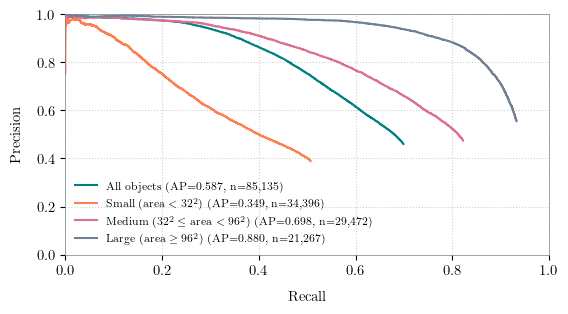

In [12]:
# Detection-area buckets (small: area < 32^2, large: area >= 96^2) for *which*
# detections go into each curve -- a standard proxy for COCOeval's own GT-area-based
# buckets. Large objects are typically easier (less localization ambiguity, less
# GDino score noise), so the split shows where the budget-1% numbers above are being
# pulled down from.
bbox_xyxy = np.vstack(pr_dataset["gdino_bbox"].to_numpy())
areas = (bbox_xyxy[:, 2] - bbox_xyxy[:, 0]) * (bbox_xyxy[:, 3] - bbox_xyxy[:, 1])
size_masks = {
    "All objects": np.ones(len(pr_dataset), dtype=bool),
    r"Small (area $< 32^2$)": areas < 32 ** 2,
    r"Medium ($32^2 \leq$ area $< 96^2$)": (areas >= 32 ** 2) & (areas < 96 ** 2),
    r"Large (area $\geq 96^2$)": areas >= 96 ** 2,
}

# But the *denominator* for a fair recall needs the real thing: true GT-box areas
# (COCOeval's actual convention), not the detection-box proxy above -- otherwise
# recall would be relative to "GT objects some held-out detection happened to
# propose a small/large box for", not "true small/large GT objects", and would
# still reach 1.0 at the lowest threshold within each bucket.
gt_areas = np.concatenate([
    (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    for boxes in (g["boxes"] for g in pr_gt_by_image.values()) if len(boxes) > 0
])
total_gt_by_size = {
    "All objects": len(gt_areas),
    r"Small (area $< 32^2$)": int((gt_areas < 32 ** 2).sum()),
    r"Medium ($32^2 \leq$ area $< 96^2$)": int(((gt_areas >= 32 ** 2) & (gt_areas < 96 ** 2)).sum()),
    r"Large (area $\geq 96^2$)": int((gt_areas >= 96 ** 2).sum()),
}

fig, ax = plt.subplots()
for label, size_mask in size_masks.items():
    m = held_out & size_mask
    if m.sum() == 0 or y_true[m].sum() == 0:
        continue
    recall_scale_s = y_true[m].sum() / total_gt_by_size[label]
    prec_s, rec_s_raw, _ = precision_recall_curve(y_true[m], bayes_scores[m])
    rec_s = rec_s_raw * recall_scale_s
    ap_s = np.trapz(prec_s[::-1], rec_s[::-1])
    ax.plot(rec_s, prec_s, lw=1.5, label=f"{label} (AP={ap_s:.3f}, n={int(m.sum()):,})")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
# ax.set_title(f"COCO, {PR_BUDGET:.0%} budget -- PLS + Bayes, by object size")
ax.grid(True, ls=":", alpha=0.6)
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig("plots/PR_curve_by_size_1pct_budget_coco.pdf", dpi=300, bbox_inches="tight")
plt.show()


In [13]:
# Does a size-specific F1-optimal threshold beat applying the single global
# threshold to each size bucket? Reuses the scores and masks above -- no refitting.
size_threshold_rows = []
for label, size_mask in size_masks.items():
    train_mask = pr_budget_mask & size_mask
    held_mask = held_out & size_mask
    if train_mask.sum() == 0 or held_mask.sum() == 0 or y_true[train_mask].sum() == 0:
        continue

    prec_tr, rec_tr, thr_tr = precision_recall_curve(y_true[train_mask], bayes_scores[train_mask])
    f1_tr = np.where((prec_tr + rec_tr) > 0, 2 * prec_tr * rec_tr / (prec_tr + rec_tr + 1e-12), 0.0)
    t_size = float(thr_tr[np.argmax(f1_tr[:-1])])

    f1_size, p_size, r_size = _f1_at(t_size, bayes_scores[held_mask], y_true[held_mask])
    f1_glob, p_glob, r_glob = _f1_at(f1_opt_threshold, bayes_scores[held_mask], y_true[held_mask])

    size_threshold_rows.append(dict(
        Population=label, size_opt_threshold=t_size, global_threshold=f1_opt_threshold,
        precision_size_opt=p_size, recall_size_opt=r_size, F1_size_opt=f1_size,
        precision_global=p_glob, recall_global=r_glob, F1_global=f1_glob,
        F1_gain=f1_size - f1_glob,
    ))

size_threshold_df = pd.DataFrame(size_threshold_rows).set_index("Population").round(4)
size_threshold_df

,size_opt_threshold,global_threshold,precision_size_opt,recall_size_opt,F1_size_opt,precision_global,recall_global,F1_global,F1_gain
Population,,,,,,,,,
All objects,0.6856,0.6856,0.8327,0.6206,0.7112,0.8327,0.6206,0.7112,0.0000
Small (area $< 32^2$),0.3701,0.6856,0.3914,0.9979,0.5623,0.7538,0.3936,0.5172,0.0451
Medium ($32^2 \leq$ area $< 96^2$),0.6990,0.6856,0.8377,0.6249,0.7158,0.8301,0.6378,0.7213,-0.0055
Large (area $\geq 96^2$),0.4742,0.6856,0.7042,0.9667,0.8148,0.8832,0.8574,0.8701,-0.0552


In [14]:
# Annotation-set-level summary at each threshold: the full budgeted 1% (already
# annotated) plus the thresholded held-out remainder. Unlike the per-size table
# above, the budget's known FPs are kept here, so they count towards
# n_annotations and FP_rate -- n_annotations exceeds the table's by exactly the
# number of FPs in the budget (printed below). GT coverage = unique GT objects
# matched (>=0.5 IoU) by anything kept.
total_gt = sum(len(g["boxes"]) for g in pr_gt_by_image.values())

def _gt_covered(kept_ds):
    covered = 0
    for image_id, rows in kept_ds.groupby("image_id"):
        gt = pr_gt_by_image.get(image_id)
        if gt is None or len(gt["boxes"]) == 0:
            continue
        pred_boxes = torch.tensor(np.vstack(rows["gdino_bbox"].to_numpy()), dtype=torch.float32)
        gt_boxes = torch.tensor(gt["boxes"], dtype=torch.float32)
        iou = _iou_matrix(pred_boxes, gt_boxes).numpy()
        best_iou_per_gt = iou.max(axis=0) if iou.size else np.zeros(len(gt["boxes"]))
        covered += int((best_iou_per_gt >= 0.5).sum())
    return covered

summary_rows = []
for label, t in THRESHOLDS.items():
    kept_held_out = pr_dataset[held_out & (bayes_scores >= t)]
    kept_budget = pr_dataset[pr_budget_mask]   # all budgeted detections, including known FPs
    final_annotations = pd.concat([kept_budget, kept_held_out])

    n_tp = int(y_true[pr_budget_mask].sum()) + int((y_true[held_out] & (bayes_scores[held_out] >= t)).sum())
    n_total = len(final_annotations)
    fp_rate = 1 - n_tp / n_total if n_total > 0 else float("nan")
    covered = _gt_covered(final_annotations)

    summary_rows.append(dict(Threshold=label, t=t, n_annotations=n_total, FP_rate=fp_rate,
                              GT_covered=covered, GT_coverage=covered / total_gt))

summary_df = pd.DataFrame(summary_rows)
print(f"Total COCO val GT objects: {total_gt:,}  |  budgeted detections: {int(pr_budget_mask.sum()):,}  "
      f"(of which known FPs: {int((~y_true.astype(bool) & pr_budget_mask).sum()):,})")
summary_df

Total COCO val GT objects: 56,067  |  budgeted detections: 856  (of which known FPs: 446)


,Threshold,t,n_annotations,FP_rate,GT_covered,GT_coverage
0,t=0.5,0.500000,49944,0.348831,32983,0.588278
1,F1-optimal (train),0.685554,30055,0.177375,25211,0.449658


# AS and AP curves across IoU thresholds

For each method already compared in the main annotation-quality benchmark
(`baseline_comparison.py`'s grid search), reconstructs that method's
own best-hyperparameter fit at a fixed budget and plots its full per-IoU-
threshold curve (0.5:0.95, the 10 standard COCO thresholds) instead of just
the single averaged summary number -- more detail on *where* a method wins
or loses along the strictness axis.

- **AS curves** at **10% budget**
- **AP curves** at **100% budget**.

Each method's winning hyperparameters are looked up directly from the
existing grid-search results CSV (no new search -- one reconstruction fit
per method per budget), selecting by max `AS_strict` (for the AS curves) or
max `AP` (for the AP curves) at that specific budget.

In [15]:
# Independent load of df_full/dataset -- cell 3 above only loads them on a cache
# miss for the AS-ceiling computation, so they may not be in scope here.
# SCORE_THR/SOFT_GT_PATH/SOFT_LABEL_THRESH/DATASET_PATH (cell 3), METHODS/
# METHODS_TO_LABELS (cell 1) and grid_results (cell 5) are reused from above.
import numpy as np

sys.path.append("../label_spreading")
from src import (label_spreading_object_conventional, knn_regression_object, gkr_object,
                  _faiss_labeled_neighbors)
from baseline_comparison import (calibrated_gdino_baseline, build_bayes_dataset,
                                  resorted_raw_baseline, sample_budget_indices,
                                  _category_aware_tp)
from evaluation import compute_map, compute_similarity

ONLY_OBJECTS = False
DATA_SPACE = "gdino_embedding"
AMGX_CONFIG = "../label_spreading/configs/FGMRES_AGGREGATION.json"
GRID_SEED = 42   # sample_budget_indices' default -- same budget sample as the grid search

df_full = pd.read_parquet(DATASET_PATH)
dataset = df_full[df_full["gdino_score"] >= SCORE_THR].copy().reset_index(drop=True)
sl = np.array([v for v in dataset["soft_label"].values])
dataset["soft_label"] = list(sl)
dataset["is_object"] = dataset["gdino_match"].astype(float)
dataset["resort_true_tp"] = _category_aware_tp(dataset, SOFT_GT_PATH, SOFT_LABEL_THRESH)
print(f"{len(dataset):,} detections (score >= {SCORE_THR})")


85,991 detections (score >= 0.2)


In [16]:
def winning_hp(method, budget, metric):
    """Row with max `metric` for this method at this budget -- the hyperparameters
    that will be reconstructed and re-evaluated for the full curve."""
    sub = grid_results[(grid_results["method"] == method) & (np.isclose(grid_results["budget"], budget))]
    if sub.empty:
        raise ValueError(f"No grid rows for method={method} budget={budget}")
    return sub.loc[sub[metric].idxmax()]


def reconstruct(method, budget, metric):
    """Re-fits `method` at its own best-`metric` hyperparameters (for this
    budget), using the SAME budget-sampled indices as the original grid search
    (identical seed) -- returns a process_data DataFrame ready for
    compute_map/compute_similarity."""
    row = winning_hp(method, budget, metric)
    indices_b = sample_budget_indices(len(dataset), budget, seed=GRID_SEED)
    n_samples_b = len(indices_b)
    tag = f"curve_{method}_{metric}_b{budget}"

    if method == "PLS":
        ds = label_spreading_object_conventional(
            tag, ONLY_OBJECTS, dataset.copy(), DATA_SPACE, "label", "soft_label", "is_object", "all",
            int(row["k"]), row["alpha"], n_samples_b, indices=indices_b, config=AMGX_CONFIG,
            bandwidth_scale=row["bandwidth_scale"],
        )
    elif method == "GKR":
        m = max(500, 0 if pd.isna(row.get("k")) else int(row.get("k", 0)))
        neighbor_cache_b = _faiss_labeled_neighbors(dataset, DATA_SPACE, indices_b, m)
        ds = gkr_object(
            tag, ONLY_OBJECTS, dataset.copy(), DATA_SPACE, "label", "soft_label", "is_object", "all",
            row["gamma"], n_samples_b, indices=indices_b, m=m, neighbor_cache=neighbor_cache_b,
        )
    elif method == "kNN":
        k = int(row["k"])
        neighbor_cache_b = _faiss_labeled_neighbors(dataset, DATA_SPACE, indices_b, max(500, k))
        ds = knn_regression_object(
            tag, ONLY_OBJECTS, dataset.copy(), DATA_SPACE, "label", "soft_label", "is_object", "all",
            k, n_samples_b, indices=indices_b, neighbor_cache=neighbor_cache_b,
        )
    elif method == "Baseline":
        ds, _ = calibrated_gdino_baseline(dataset, df_full, budget, tag, ONLY_OBJECTS, DATA_SPACE)
    elif method == "Bayes":
        # Bayes blends ITS OWN winning (k, alpha, bandwidth) PLS fit (recorded in the same
        # row -- Bayes never searches k/alpha/bandwidth itself, only kappa) with the
        # calibrated-GDino prior at that row's winning kappa.
        pls_ds = label_spreading_object_conventional(
            f"{tag}_pls", ONLY_OBJECTS, dataset.copy(), DATA_SPACE, "label", "soft_label", "is_object", "all",
            int(row["k"]), row["alpha"], n_samples_b, indices=indices_b, config=AMGX_CONFIG,
            bandwidth_scale=row["bandwidth_scale"],
        )
        _, p_hat_baseline_b = calibrated_gdino_baseline(dataset, df_full, budget, f"{tag}_base",
                                                          ONLY_OBJECTS, DATA_SPACE)
        pls_trials = pls_ds["trials"].to_numpy()
        pls_p_hat = np.vstack(pls_ds["p_hat"].to_numpy())
        F_pls = pls_p_hat * pls_trials[:, None]
        ds = build_bayes_dataset(row["kappa"], p_hat_baseline_b, F_pls, pls_ds, tag,
                                  int(row["k"]), row["alpha"], n_samples_b, ONLY_OBJECTS, DATA_SPACE, AMGX_CONFIG)
    elif method == "Resort":
        ds = resorted_raw_baseline(dataset, indices_b, tag, ONLY_OBJECTS, DATA_SPACE)
    else:
        raise ValueError(method)
    return ds

## AS curves, 10% budget

In [17]:
# AS (AS_strict): zero similarity credit for false positives
BUDGET_AS = 0.10
as_curves = {}
as_pr_curves = {}
for method in METHODS:
    ds = reconstruct(method, BUDGET_AS, "AS_strict")
    res = compute_similarity(ds, soft_gt_path=SOFT_GT_PATH, return_curve=True, pr_curve_iou=0.5)
    as_curves[method] = res["AS_strict_curve"]
    as_pr_curves[method] = res["AS_strict_pr_curve"]

as_curve_df = pd.DataFrame(as_curves)
as_curve_df.index.name = "iou_thresh"
as_curve_df.to_csv("tables/as_strict_curves_budget10.csv")
as_curve_df

use pre-defined indices


use pre-defined indices


,PLS,GKR,kNN,Baseline,Resort,Bayes
iou_thresh,,,,,,
0.50,0.547640,0.552908,0.499941,0.453988,0.450730,0.520459
0.55,0.526654,0.530950,0.478997,0.438950,0.432492,0.502029
0.60,0.497197,0.500615,0.449121,0.418022,0.407776,0.475935
0.65,0.463687,0.466443,0.414954,0.393792,0.380458,0.445686
0.70,0.420851,0.422503,0.372257,0.362258,0.344619,0.406753
0.75,0.364785,0.365444,0.315971,0.319703,0.299029,0.355472
0.80,0.297905,0.297604,0.251394,0.267449,0.244020,0.293472
0.85,0.219845,0.218319,0.176699,0.202904,0.179545,0.218720
0.90,0.134168,0.131945,0.095655,0.127447,0.109493,0.134795


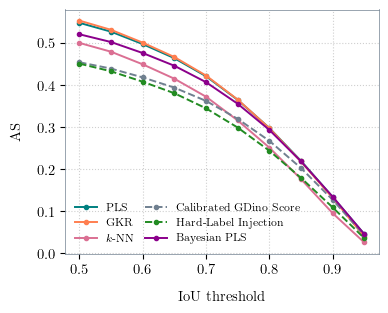

In [18]:
FIGSIZE = (4, 3.25)
fig, ax = plt.subplots(figsize=FIGSIZE)
for method in METHODS:
    linestyle = "dashed" if method in ["Baseline", "Resort"] else "solid"
    xs = sorted(as_curves[method].keys())
    ys = [as_curves[method][x] for x in xs]
    ax.plot(xs, ys, marker="o", markersize=3, linewidth=1.4, label=METHODS_TO_LABELS[method], linestyle=linestyle)
ax.set_xlabel("IoU threshold")
ax.set_ylabel("AS")
ax.grid(True, ls=":", alpha=0.6)
ax.legend(fontsize=8, ncols=2, columnspacing=1, frameon=False)
plt.tight_layout()
plt.savefig("plots/as_for_different_ious_budget10.pdf", dpi=300, bbox_inches="tight")
plt.show()

## Similarity-recall curve at IoU=0.5, 10% budget

One curve over all classes -- AS is category-agnostic by construction (it compares full soft-label distributions box-for-box, not per-class counts), so unlike the AP curve below it requires no averaging over classes.

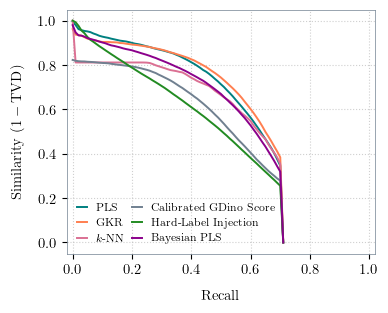

In [19]:
ap_pr_csv_rows = []


def clip_to_last_nonzero(xs, ys):
    """COCOeval-style interpolated curves are defined on a FIXED recall grid
    (0..1) regardless of what's actually achievable -- once real detections
    run out, the remaining grid points are left at their initialized value,
    0, producing a flat trailing line rather than a genuine "reached zero
    recall" data point. Clips right after the last real nonzero point so the
    plotted curve visibly reaches 0 once, instead of trailing a flat zero
    line out to recall=1.0."""
    import numpy as np
    xs, ys = np.asarray(xs), np.asarray(ys)
    nz = np.where(ys > 0)[0]
    if len(nz) == 0:
        return xs, ys
    end = min(nz[-1] + 2, len(ys))
    return xs[:end], ys[:end]


fig, ax = plt.subplots(figsize=FIGSIZE)
for method in METHODS:
    curve = as_pr_curves[method]
    xs, ys = clip_to_last_nonzero(curve["recall"], curve["similarity"])
    ax.plot(xs, ys, linewidth=1.4, label=METHODS_TO_LABELS[method])
    for r, s in zip(curve["recall"], curve["similarity"]):
        ap_pr_csv_rows.append(dict(method=method, recall=r, similarity=s))
ax.set_xlabel("Recall")
ax.set_ylabel(r"Similarity ($1-\mathrm{TVD}$)")
ax.set_xlim(-0.02, 1.02)
ax.grid(True, ls=":", alpha=0.6)
ax.legend(fontsize=8, ncols=2, columnspacing=0.8, handlelength=0.9, frameon=False)
plt.tight_layout()
plt.savefig("plots/as_curves_iou50_budget10.pdf", dpi=300, bbox_inches="tight")
plt.show()

pd.DataFrame(ap_pr_csv_rows).to_csv("tables/as_curves_iou50_budget10.csv", index=False)

## AP curves, 100% budget

In [20]:
BUDGET_AP = 1.00
ap_curves = {}
ap_pr_curves = {}
for method in METHODS:
    ds = reconstruct(method, BUDGET_AP, "AP")
    res = compute_map(ds, soft_gt_path=SOFT_GT_PATH, return_curve=True, pr_curve_iou=0.5)
    ap_curves[method] = res["AP_curve"]
    ap_pr_curves[method] = res["AP_pr_curve"]

ap_curve_df = pd.DataFrame(ap_curves)
ap_curve_df.index.name = "iou_thresh"
ap_curve_df.to_csv("tables/ap_curves_budget100.csv")
ap_curve_df

use pre-defined indices


use pre-defined indices


,PLS,GKR,kNN,Baseline,Resort,Bayes
iou_thresh,,,,,,
0.50,0.750113,0.739106,0.691275,0.674587,0.777220,0.744087
0.55,0.727551,0.716947,0.673381,0.657865,0.749474,0.721303
0.60,0.697649,0.687812,0.648812,0.635500,0.713998,0.692059
0.65,0.664543,0.655937,0.620843,0.610169,0.676313,0.659789
0.70,0.619313,0.611388,0.582804,0.574174,0.625205,0.615712
0.75,0.563309,0.555830,0.530600,0.527480,0.562712,0.560903
0.80,0.487472,0.480330,0.463402,0.463630,0.481509,0.486781
0.85,0.388133,0.383017,0.372925,0.375106,0.378650,0.387825
0.90,0.272167,0.266431,0.263975,0.266361,0.260405,0.271460


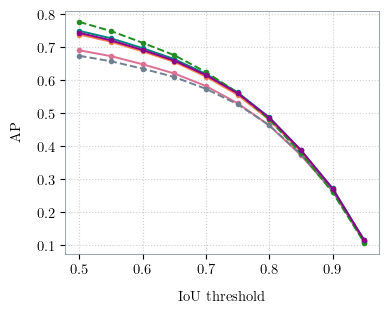

In [21]:
fig, ax = plt.subplots(figsize=FIGSIZE)
for method in METHODS:
    linestyle = "dashed" if method in ["Baseline", "Resort"] else "solid"
    xs = sorted(ap_curves[method].keys())
    ys = [ap_curves[method][x] for x in xs]
    ax.plot(xs, ys, marker="o", markersize=3, linewidth=1.4, label=METHODS_TO_LABELS[method], linestyle=linestyle)
ax.set_xlabel("IoU threshold")
ax.set_ylabel("AP")
ax.grid(True, ls=":", alpha=0.6)
#ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig("plots/ap_for_different_ious_budget100.pdf", dpi=300, bbox_inches="tight")
plt.show()

## Precision-recall curve at IoU=0.5, 100% budget

One curve over all classes -- COCOeval computes precision separately per category at each recall level, so this is the mean over the 80 COCO categories at each recall level (the same averaging "AP" itself does, just keeping the curve shape instead of collapsing it to one number).

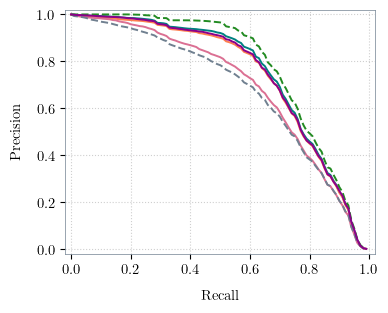

In [22]:
pr_csv_rows = []
fig, ax = plt.subplots(figsize=FIGSIZE)
for method in METHODS:
    linestyle = "dashed" if method in ["Baseline", "Resort"] else "solid"
    curve = ap_pr_curves[method]
    xs, ys = clip_to_last_nonzero(curve["recall"], curve["precision"])
    ax.plot(xs, ys, linewidth=1.4, label=METHODS_TO_LABELS[method], linestyle=linestyle)
    for r, p in zip(curve["recall"], curve["precision"]):
        pr_csv_rows.append(dict(method=method, recall=r, precision=p))
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.grid(True, ls=":", alpha=0.6)
#ax.legend(fontsize=10, ncols=2, frameon=False)
plt.tight_layout()
plt.savefig("plots/ap_curves_iou50_budget100.pdf", dpi=300, bbox_inches="tight")
plt.show()

pd.DataFrame(pr_csv_rows).to_csv("tables/ap_curves_iou50_budget100.csv", index=False)

# Hyperparameter study (COCO)

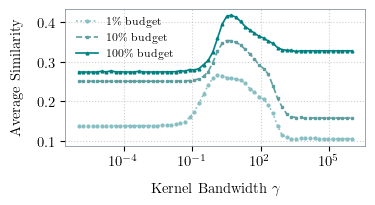

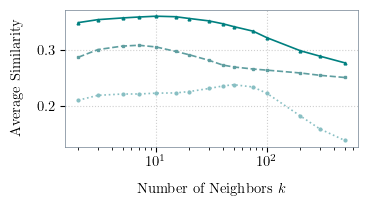

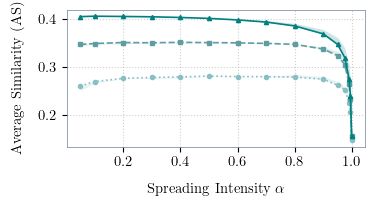

In [23]:
# AS vs. hyperparameter, at three budgets, for each parametrized method individually
# (GKR/kNN have one parameter each; for PLS the line shows k=20, see below)

SWEEP_FIGSIZE = (5.8 * 2 / 3, (9 / 16) * 5.8 * 2 / 3)   # 2/3-scaled, also used by the heatmaps below

BUDGET_LABELS = {b: rf"{b * 100:g}\% budget" for b in BUDGETS_TO_DISPLAY}
BUDGET_MARKERS = {0.01: "o", 0.1: "s", 1.0: "^"}
BUDGET_LINESTYLES = {0.01: "dotted", 0.1: "--", 1.0: "-"}
BUDGET_COLORS = {0.01: "#88bfc3", 0.1: "cadetblue", 1.0: "teal"}

def plot_as_vs_param(ax, sub_df, param, xlabel, xscale="log", legend=True):
    for budget in BUDGETS_TO_DISPLAY:
        sub = sub_df[sub_df["budget"] == budget].sort_values(param)
        ax.plot(sub[param], sub[AS], marker=BUDGET_MARKERS[budget], linestyle=BUDGET_LINESTYLES[budget], color=BUDGET_COLORS[budget],
                 markersize=2, linewidth=1.2, label=BUDGET_LABELS[budget])
    ax.set_xscale(xscale)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Average Similarity")
    ax.grid(True, ls=":", alpha=0.6)
    if legend:
        ax.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(0.02, 0.98), borderaxespad=0.0)


# GKR: AS vs. kernel bandwidth gamma
gkr = grid_results[grid_results["method"] == "GKR"]
fig, ax = plt.subplots(figsize=SWEEP_FIGSIZE)
plot_as_vs_param(ax, gkr, "gamma", r"Kernel Bandwidth $\gamma$")
plt.tight_layout()
plt.savefig("plots/GKR_gamma_sweep.pdf", dpi=300, bbox_inches="tight")
plt.show()

# kNN: AS vs. number of neighbors k
knn = grid_results[grid_results["method"] == "kNN"]
fig, ax = plt.subplots(figsize=SWEEP_FIGSIZE)
plot_as_vs_param(ax, knn, "k", r"Number of Neighbors $k$", legend=False)
plt.tight_layout()
plt.savefig("plots/kNN_k_sweep.pdf", dpi=300, bbox_inches="tight")
plt.show()

# PLS: AS vs. alpha. The grid varies k in {10, 20} and 5 bandwidth_scale values; each
# (k, alpha) shows its best bandwidth_scale. Line: k=20. Band: min/max over k.
pls = grid_results[grid_results["method"] == "PLS"]
pls_best_bw = pls.groupby(["budget", "k", "alpha"], as_index=False)[AS].max()

fig, ax = plt.subplots(figsize=SWEEP_FIGSIZE)
for budget in BUDGETS_TO_DISPLAY:
    color = BUDGET_COLORS[budget]
    piv = pls_best_bw[pls_best_bw["budget"] == budget].pivot(index="alpha", columns="k", values=AS).sort_index()
    ax.fill_between(piv.index, piv.min(axis=1), piv.max(axis=1), color=color, alpha=0.2, linewidth=0)
    sub = pls_best_bw[(pls_best_bw["budget"] == budget) & (pls_best_bw["k"] == 20)].sort_values("alpha")
    ax.plot(sub["alpha"], sub[AS], marker=BUDGET_MARKERS[budget], linestyle=BUDGET_LINESTYLES[budget],
             color=color, markersize=3, linewidth=1.2, label=BUDGET_LABELS[budget])
ax.set_xlabel(r"Spreading Intensity $\alpha$")
ax.set_ylabel("Average Similarity (AS)")
ax.grid(True, ls=":", alpha=0.6)
plt.tight_layout()
plt.savefig("plots/PLS_alpha_sweep.pdf", dpi=300, bbox_inches="tight")
plt.show()


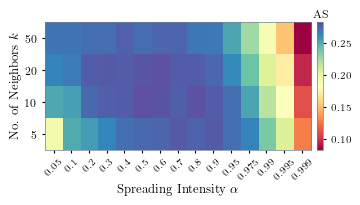

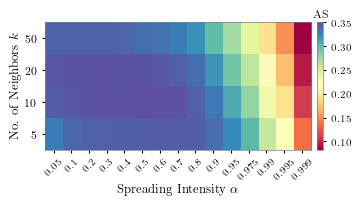

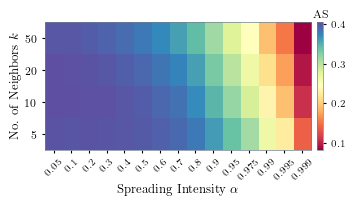

In [24]:
# PLS: AS heatmap over the (alpha, k) grid, one plot per budget, showing the alpha/k
# interaction that the alpha sweep above summarizes as a band.
#
# Uses a separate PLS sweep over k in {5, 10, 20, 50} at a fixed bandwidth (no
# bandwidth_scale search) instead of the k in {10, 20} x bandwidth_scale grid used
# elsewhere in this notebook, so its values are not directly comparable to the other
# AS numbers; the plot is meant qualitatively. Each budget has its own color scale.
PLS_4K_CSV = ("experiments/coco_val_baseline_comp_simple/grid_search/"
              "coco_val_baseline_comp_simple_pls_k_sweep_results.csv")
pls_4k = pd.read_csv(PLS_4K_CSV)
pls_4k = pls_4k[pls_4k["method"] == "PLS"]

alphas = sorted(pls_4k["alpha"].unique())
ks = sorted(pls_4k["k"].unique())

for budget in BUDGETS_TO_DISPLAY:
    piv = (pls_4k[pls_4k["budget"] == budget]
           .pivot_table(index="k", columns="alpha", values=AS)
           .reindex(index=ks, columns=alphas))

    fig, ax = plt.subplots(figsize=SWEEP_FIGSIZE)
    im = ax.imshow(piv.values, aspect="auto", origin="lower", cmap="Spectral")

    ax.set_xticks(range(len(alphas)))
    ax.set_xticklabels([f"{a:g}" for a in alphas], rotation=45, fontsize=7)
    ax.set_yticks(range(len(ks)))
    ax.set_yticklabels([f"{k:g}" for k in ks], fontsize=8)
    ax.tick_params(axis="both", length=2)

    ax.set_xlabel(r"Spreading Intensity $\alpha$", fontsize=9, labelpad=2)
    ax.set_ylabel(r"No. of Neighbors $k$", fontsize=9, labelpad=3)

    cbar = fig.colorbar(im, ax=ax, pad=0.02)
    cbar.ax.set_title("AS", fontsize=8, pad=4)
    cbar.ax.tick_params(labelsize=7, length=2)

    plt.tight_layout()
    plt.savefig(f"plots/PLS_heatmap_{budget * 100:g}pct.pdf", dpi=300, bbox_inches="tight")
    plt.show()

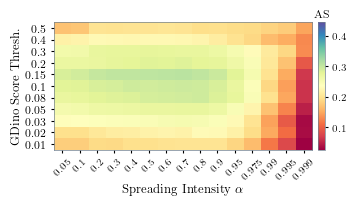

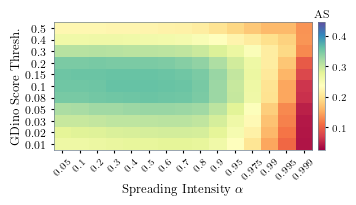

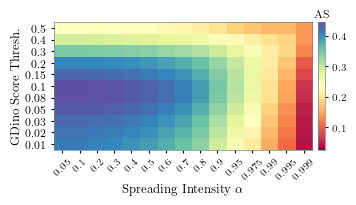

In [25]:
# PLS: AS heatmap over the (GDino score threshold, alpha) grid -- same style as the
# (alpha, k) heatmap above, but sweeping the detection-score prefilter instead of k
# (which is pinned to 20 here too). Source: label_spreading/gdino_score_analysis.ipynb's
# grid search over score_thr x alpha at the same three budgets. One plot per budget,
# with a shared color scale so hue is directly comparable budget-to-budget.

GDINO_SCORE_CSV = "experiments/gdino_score_analysis/grid_search/gdino_score_analysis_grid_search_results.csv"
gdino_score_results = pd.read_csv(GDINO_SCORE_CSV)
gdino_score_results = gdino_score_results[gdino_score_results["method"] == "PLS"]

score_thrs = sorted(gdino_score_results["score_thr"].unique())
score_alphas = sorted(gdino_score_results["alpha"].unique())

as_min = gdino_score_results[gdino_score_results["budget"].isin(BUDGETS_TO_DISPLAY)][AS].min()
as_max = gdino_score_results[gdino_score_results["budget"].isin(BUDGETS_TO_DISPLAY)][AS].max()

for budget in BUDGETS_TO_DISPLAY:
    piv = (gdino_score_results[gdino_score_results["budget"] == budget]
           .pivot_table(index="score_thr", columns="alpha", values=AS)
           .reindex(index=score_thrs, columns=score_alphas))

    fig, ax = plt.subplots(figsize=SWEEP_FIGSIZE)
    im = ax.imshow(piv.values, aspect="auto", origin="lower", cmap="Spectral", vmin=as_min, vmax=as_max)

    ax.set_xticks(range(len(score_alphas)))
    ax.set_xticklabels([f"{a:g}" for a in score_alphas], rotation=45, fontsize=7)
    ax.set_yticks(range(len(score_thrs)))
    ax.set_yticklabels([f"{s:g}" for s in score_thrs], fontsize=8)
    ax.tick_params(axis="both", length=2)

    ax.set_xlabel(r"Spreading Intensity $\alpha$", fontsize=9, labelpad=2)
    ax.set_ylabel("GDino Score Thresh.", fontsize=9, labelpad=3)

    cbar = fig.colorbar(im, ax=ax, pad=0.02)
    cbar.ax.set_title("AS", fontsize=8, pad=4)
    cbar.ax.tick_params(labelsize=7, length=2)

    plt.tight_layout()
    plt.savefig(f"plots/PLS_gdino_score_heatmap_{budget * 100:g}pct.pdf", dpi=300, bbox_inches="tight")
    plt.show()

# Summary table: AP / AS across datasets, methods & budgets

All 6 methods x 4 datasets (COCO, Cityscapes, KITTI, Pascal VOC) x 3 budgets
(1%, 10%, 100%). AP and AS are `best_AP` / `best_AS_strict` from `best_tables`,
i.e. derived from each dataset's full grid-search results by
`best_metrics_table`, with each metric at its own best hyperparameters (same
as the plots above). Written to `tables/as_ap_comparison.tex`.

In [26]:
ALL_DATASETS = {
    "COCO": dict(dataset_key="coco_val"),
    "Cityscapes": dict(dataset_key="cityscapes_trainval"),
    "KITTI": dict(dataset_key="kitti_train"),
    "Pascal VOC": dict(dataset_key="voc_trainval"),
}

TABLE_BUDGETS = [0.01, 0.1, 1.0]  # 1%, 10%, 100%


summary_rows = []
for dataset_name, d in ALL_DATASETS.items():
    bt = best_tables[d["dataset_key"]]
    for method in METHODS:
        for budget in TABLE_BUDGETS:
            match = bt[(bt["method"] == method) & np.isclose(bt["budget"], budget)]
            if match.empty:
                continue
            row = match.iloc[0]
            summary_rows.append({
                "Dataset": dataset_name,
                "Budget": budget,
                "Method": METHODS_TO_LABELS[method],
                "AP": row["best_AP"] * 100,
                "AS": row["best_AS_strict"] * 100,
            })

summary_df = pd.DataFrame(summary_rows)
summary_df

,Dataset,Budget,Method,AP,AS
0,COCO,0.01,PLS,46.021915,28.477314
1,COCO,0.10,PLS,49.408090,35.172692
2,COCO,1.00,PLS,52.851018,40.605066
3,COCO,0.01,GKR,48.502962,26.612104
4,COCO,0.10,GKR,49.190708,35.267267
...,...,...,...,...,...
67,Pascal VOC,0.10,Hard-Label Injection,69.134432,51.733773
68,Pascal VOC,1.00,Hard-Label Injection,70.972030,62.983717
69,Pascal VOC,0.01,Bayesian PLS,69.586059,61.659309
70,Pascal VOC,0.10,Bayesian PLS,69.773262,63.322049


In [27]:
os.makedirs("tables", exist_ok=True)

budget_col_labels = [rf"{b * 100:g}\%" for b in TABLE_BUDGETS]
summary_df["BudgetLabel"] = summary_df["Budget"].map(lambda b: rf"{b * 100:g}\%")

DATASET_NAMES = list(ALL_DATASETS.keys())
# Row order for this table only (the global METHODS order is kept for the plots).
TABLE_METHODS = ["PLS", "Bayes", "GKR", "kNN", "Baseline", "Resort"]
METHOD_LABELS = [METHODS_TO_LABELS[m] for m in TABLE_METHODS]


def get_piv(metric):
    piv = summary_df.pivot_table(index="Method", columns=["Dataset", "BudgetLabel"], values=metric)
    piv = piv.reindex(index=METHOD_LABELS)
    piv = piv.reindex(columns=pd.MultiIndex.from_product([DATASET_NAMES, budget_col_labels]))
    return piv


def format_column(vals):
    """Bold the best value in a column, underline the second-best -- based on the
    DISPLAYED (1-decimal-rounded) value, so values that display identically (e.g.
    two methods both rounding to 30.3) are marked consistently rather than one
    winning by an invisible fourth-decimal difference."""
    vals = np.asarray(vals, dtype=float)
    rounded = np.round(vals, 1)
    best = rounded.max()
    below_best = rounded[rounded < best]
    second = below_best.max() if len(below_best) > 0 else None

    out = []
    for v, r in zip(vals, rounded):
        s = f"{v:.1f}"
        if r == best:
            s = f"\\textbf{{{s}}}"
        elif second is not None and r == second:
            s = f"\\underline{{{s}}}"
        out.append(s)
    return out


def make_subtable(metric, subcaption, sublabel):
    """Hand-rolled (not pandas.to_latex) so we get: a vertical rule separating each
    dataset's 3-budget block from its neighbors, the "Method" header on the same
    line as the budget columns instead of its own separate row, and per-column
    bold-best/underline-second-best highlighting (computed per (dataset, budget)
    column, across all 6 methods)."""
    piv = get_piv(metric)
    n_datasets = len(DATASET_NAMES)
    colspec = "l" + "|rrr" * n_datasets

    dataset_header = " & " + " & ".join(f"\\multicolumn{{3}}{{c}}{{{d}}}" for d in DATASET_NAMES) + r" \\"
    budget_header = "Method & " + " & ".join(budget_col_labels * n_datasets) + r" \\"

    columns = [(d, b) for d in DATASET_NAMES for b in budget_col_labels]
    raw = np.array([[piv.loc[m, c] for c in columns] for m in METHOD_LABELS])
    formatted = np.empty(raw.shape, dtype=object)
    for j in range(raw.shape[1]):
        formatted[:, j] = format_column(raw[:, j])

    rows = []
    for i, method_label in enumerate(METHOD_LABELS):
        rows.append(f"{method_label} & " + " & ".join(formatted[i]) + r" \\")

    # \resizebox scales the tabular to exactly \linewidth of the two-column table*.
    body_lines = [
        r"\resizebox{\linewidth}{!}{%",
        f"\\begin{{tabular}}{{{colspec}}}",
        r"\toprule",
        dataset_header,
        budget_header,
        r"\midrule",
        *rows,
        r"\bottomrule",
        r"\end{tabular}",
        r"}",
    ]
    lines = [
        r"\begin{subtable}[t]{\linewidth}",
        r"\centering",
        f"\\caption{{{subcaption}}}",
        f"\\label{{tab:{sublabel}}}",
        *body_lines,
        r"\end{subtable}",
    ]
    return "\n".join(lines)


# needs \usepackage{booktabs} (for \toprule/\midrule/\bottomrule), \usepackage{subcaption}
# (for the subtable environment), and \usepackage{graphicx} (for \resizebox) in the LaTeX doc
as_subtable = make_subtable("AS", "Average Similarity (AS)", "as_comparison")
ap_subtable = make_subtable("AP", "Average Precision (AP)", "ap_comparison")

# table* spans both columns in a two-column layout
as_ap_table = "\n".join([
    r"\begin{table*}[t]",
    r"\centering",
    r"\caption{AS and AP (\%) across datasets, methods, and annotation budgets.}",
    r"\label{tab:as_ap_comparison}",
    as_subtable,
    r"\bigskip",
    ap_subtable,
    r"\end{table*}",
])

print(as_ap_table)

with open("tables/as_ap_comparison.tex", "w") as f:
    f.write(f"%% ---- AS/AP table (two subtables) ----\n{as_ap_table}\n")
print("Saved -> analysis/tables/as_ap_comparison.tex")

\begin{table*}[t]
\centering
\caption{AS and AP (\%) across datasets, methods, and annotation budgets.}
\label{tab:as_ap_comparison}
\begin{subtable}[t]{\linewidth}
\centering
\caption{Average Similarity (AS)}
\label{tab:as_comparison}
\resizebox{\linewidth}{!}{%
\begin{tabular}{l|rrr|rrr|rrr|rrr}
\toprule
 & \multicolumn{3}{c}{COCO} & \multicolumn{3}{c}{Cityscapes} & \multicolumn{3}{c}{KITTI} & \multicolumn{3}{c}{Pascal VOC} \\
Method & 1\% & 10\% & 100\% & 1\% & 10\% & 100\% & 1\% & 10\% & 100\% & 1\% & 10\% & 100\% \\
\midrule
PLS & \textbf{28.5} & \underline{35.2} & \underline{40.6} & \textbf{39.0} & \underline{39.4} & \textbf{41.3} & 42.3 & \underline{43.8} & 46.3 & 58.2 & \underline{61.4} & \underline{65.7} \\
Bayesian PLS & \underline{27.5} & 34.0 & 39.8 & 36.0 & 38.4 & 40.7 & 41.6 & 43.4 & \underline{46.4} & \textbf{61.7} & \textbf{63.3} & 65.6 \\
GKR & 26.6 & \textbf{35.3} & \textbf{41.6} & \underline{38.8} & \textbf{39.7} & \underline{41.1} & \textbf{43.5} & \textbf{44.4} & \